# Predicting Apple (AAPL) Stock Prices with Linear Regression

This notebook builds a simple, transparent machine-learning pipeline to forecast **Apple's next-day stock price and return** using historical market data.

The goal is not to "beat the market", but to show a rigorous workflow and, above all, an **honest evaluation** against naive baselines, which is where most stock-prediction projects go wrong.

**What this notebook covers**

1. Load 5 years of daily AAPL data from Yahoo Finance
2. Clean the data
3. Engineer features (returns, moving averages, volatility)
4. Split train / test **chronologically** (no look-ahead bias)
5. Train a Linear Regression model on next-day **price**
6. Evaluate it against a naive "tomorrow = today" baseline
7. Visualize predictions and errors
8. Reframe the problem: predict next-day **returns**
9. Add market context (S&P 500 and VIX) and compare models

**Tech stack:** Python · pandas · NumPy · scikit-learn · matplotlib · seaborn · yfinance

## Setup

In [1]:
# Uncomment when running on Google Colab or a fresh environment
# !pip install -q --upgrade yfinance

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import yfinance as yf

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)

/private/tmp/claude-504/-Users-Josue-Documents-1CODING-ML-APPLE-STOCKS-REGRESSION-MODEL/eba8212e-5f46-4f5c-8962-f64a739115d8/scratchpad/venv/lib/python3.9/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(


In [2]:
# Configuration
TICKER = "AAPL"
START = "2021-10-01"   # fixed dates make the results reproducible
END = "2026-10-01"
TRAIN_RATIO = 0.8

## Step 1: Load the data

Daily OHLCV (Open, High, Low, Close, Volume) prices are downloaded from Yahoo Finance via `yfinance`.

In [3]:
raw = yf.Ticker(TICKER).history(start=START, end=END)

print(f"Data shape: {raw.shape}")
raw.head()

Data shape: (1254, 7)


,Open,High,Low,Close,Volume,Dividends,Stock Splits
Date,,,,,,,
2021-10-01 00:00:00-04:00,138.405160,139.400043,135.683881,139.136688,94639600,0.0,0.0
2021-10-04 00:00:00-04:00,138.268618,138.707547,134.864582,135.713150,98322000,0.0,0.0
2021-10-05 00:00:00-04:00,136.054532,138.736802,135.927729,137.634628,80861100,0.0,0.0
2021-10-06 00:00:00-04:00,136.035043,138.649031,134.962129,138.502731,83221100,0.0,0.0
2021-10-07 00:00:00-04:00,139.536609,140.668044,139.204987,139.760941,61732700,0.0,0.0


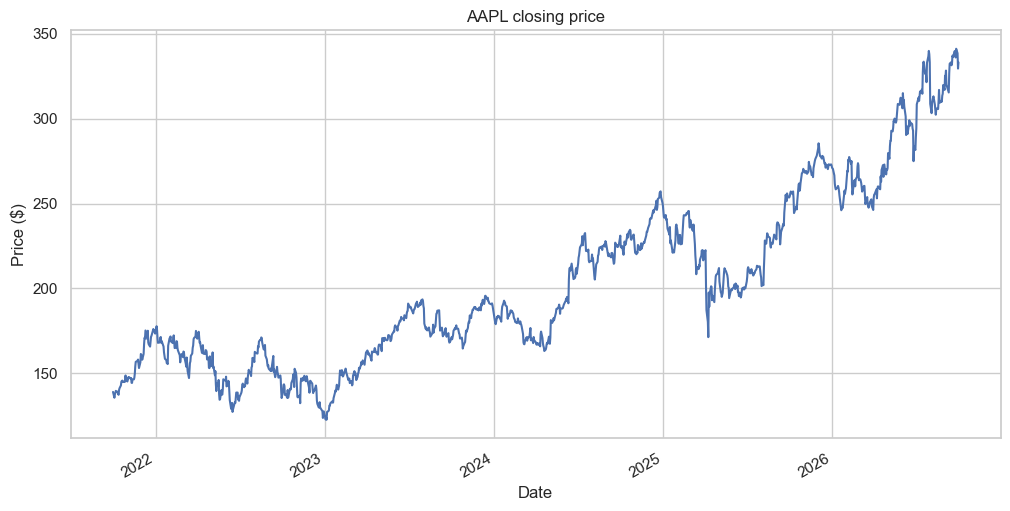

In [4]:
raw["Close"].plot(title=f"{TICKER} closing price")
plt.ylabel("Price ($)")
plt.show()

## Step 2: Clean the data

Keep only the relevant columns, remove the timezone information, sort by date and drop missing values.

In [5]:
df = raw[["Open", "High", "Low", "Close", "Volume"]].copy()
df.index = df.index.tz_localize(None)
df = df.sort_index()

print("Missing values per column:")
print(df.isna().sum())
df = df.dropna()

Missing values per column:
Open      0
High      0
Low       0
Close     0
Volume    0
dtype: int64


## Step 3: Feature engineering and target

| Feature | Description |
|---|---|
| `Close` | Today's closing price |
| `Return` | Daily percentage change of the close |
| `MA_5` / `MA_20` | 5-day and 20-day moving averages (short / medium-term trend) |
| `Volatility_5` | 5-day rolling standard deviation of returns |

**Target:** tomorrow's closing price (`Close` shifted by -1 day).

In [6]:
df["Return"] = df["Close"].pct_change()
df["MA_5"] = df["Close"].rolling(5).mean()
df["MA_20"] = df["Close"].rolling(20).mean()
df["Volatility_5"] = df["Return"].rolling(5).std()

df["Target"] = df["Close"].shift(-1)

df = df.dropna()
df[["Close", "Target", "MA_5"]].head()

,Close,Target,MA_5
Date,,,
2021-10-28,148.812378,146.110611,145.929175
2021-10-29,146.110611,145.291306,146.145712
2021-11-01,145.291306,146.325211,146.208139
2021-11-02,146.325211,147.758987,146.344693
2021-11-03,147.758987,147.242020,146.859698


## Step 4: Train / test split by time

With time series, a random split would leak future information into the training set. Instead, the **first 80%** of days are used for training and the **last 20%** for testing.

In [7]:
FEATURES = ["Close", "Return", "MA_5", "MA_20", "Volatility_5"]

X = df[FEATURES]
y = df["Target"]

split = int(len(df) * TRAIN_RATIO)

X_train, X_test = X.iloc[:split], X.iloc[split:]
y_train, y_test = y.iloc[:split], y.iloc[split:]

print(f"Train: {len(X_train)} days ({X_train.index.min().date()} to {X_train.index.max().date()})")
print(f"Test:  {len(X_test)} days ({X_test.index.min().date()} to {X_test.index.max().date()})")

Train: 987 days (2021-10-28 to 2025-10-03)
Test:  247 days (2025-10-06 to 2026-09-29)


## Step 5: Build the model

In [8]:
model = LinearRegression()
model.fit(X_train, y_train)

print(f"Intercept: {model.intercept_:.4f}\n")
print("Coefficients:")
print(pd.Series(model.coef_, index=FEATURES).round(4))

Intercept: 1.1376

Coefficients:
Close            1.0282
Return           1.7173
MA_5            -0.0765
MA_20            0.0449
Volatility_5   -24.7969
dtype: float64


## Step 6: Evaluate the model

The model is compared with a **naive baseline**: *tomorrow's price = today's price*. A model is only useful if it beats this baseline.

In [9]:
y_pred = model.predict(X_test)
baseline = X_test["Close"]

def regression_report(y_true, y_hat):
    return {
        "MAE": mean_absolute_error(y_true, y_hat),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_hat)),
        "R2": r2_score(y_true, y_hat),
    }

pd.DataFrame(
    [regression_report(y_test, y_pred), regression_report(y_test, baseline)],
    index=["Linear Regression", "Baseline (today's close)"],
).round(4)

,MAE,RMSE,R2
Linear Regression,3.2366,4.5734,0.9709
Baseline (today's close),3.1998,4.5288,0.9714


> **Interpretation:** the very high R² looks impressive, but the naive baseline scores almost exactly the same. Stock prices are highly autocorrelated: today's price is already an excellent guess for tomorrow's. The model has mostly learned to copy today's close, which the regression plot below confirms.

## Step 7: Visualize the results

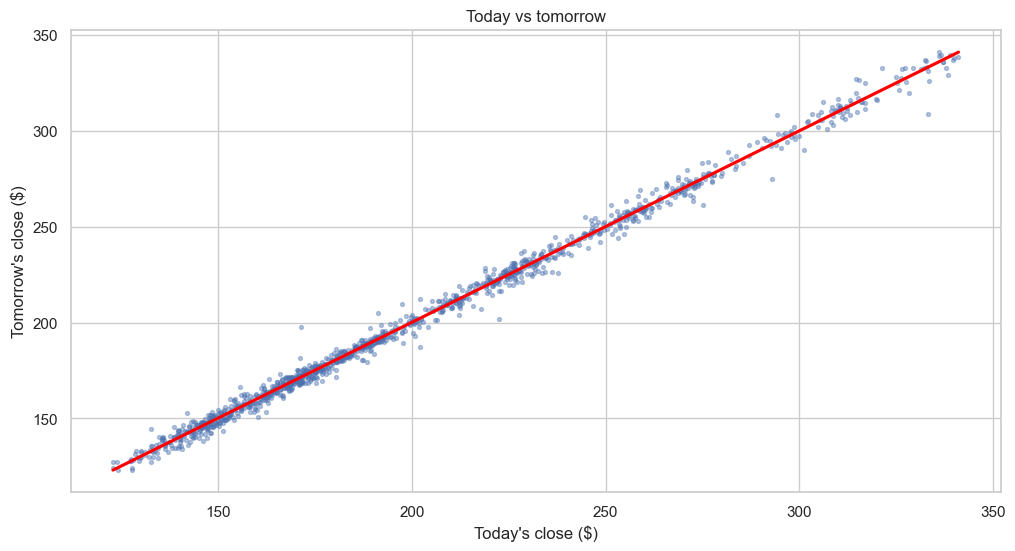

In [10]:
# Today's close vs tomorrow's close
sns.regplot(x=df["Close"], y=df["Target"],
            scatter_kws={"s": 8, "alpha": 0.4}, line_kws={"color": "red"})
plt.xlabel("Today's close ($)")
plt.ylabel("Tomorrow's close ($)")
plt.title("Today vs tomorrow")
plt.show()

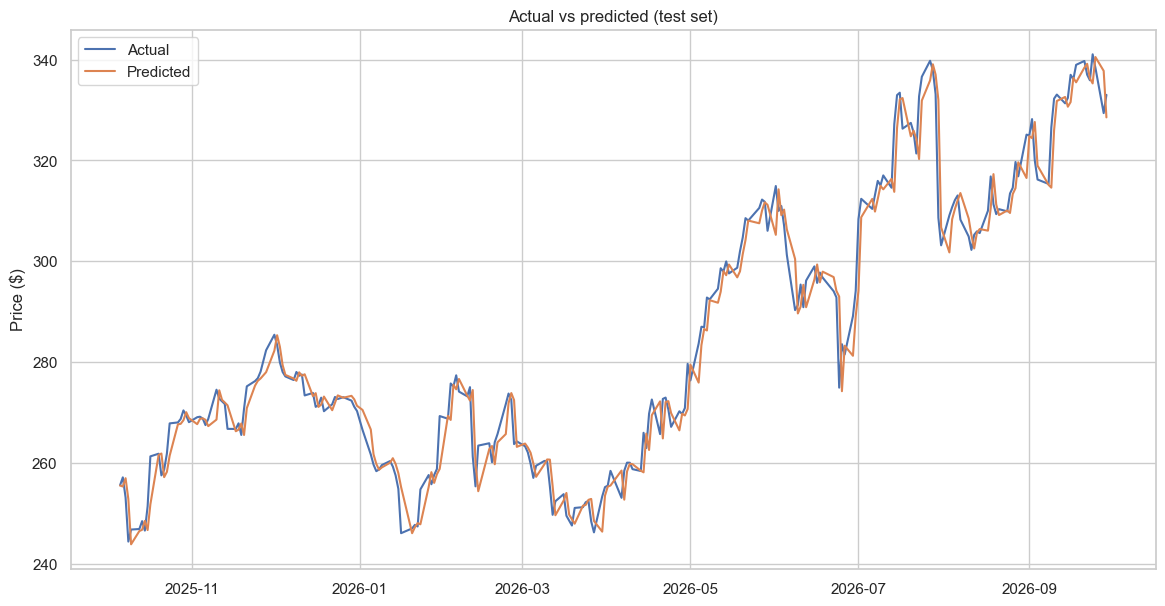

In [11]:
# Actual vs predicted over the test period
plt.figure(figsize=(14, 7))
plt.plot(y_test.index, y_test, label="Actual")
plt.plot(y_test.index, y_pred, label="Predicted")
plt.legend()
plt.title("Actual vs predicted (test set)")
plt.ylabel("Price ($)")
plt.show()

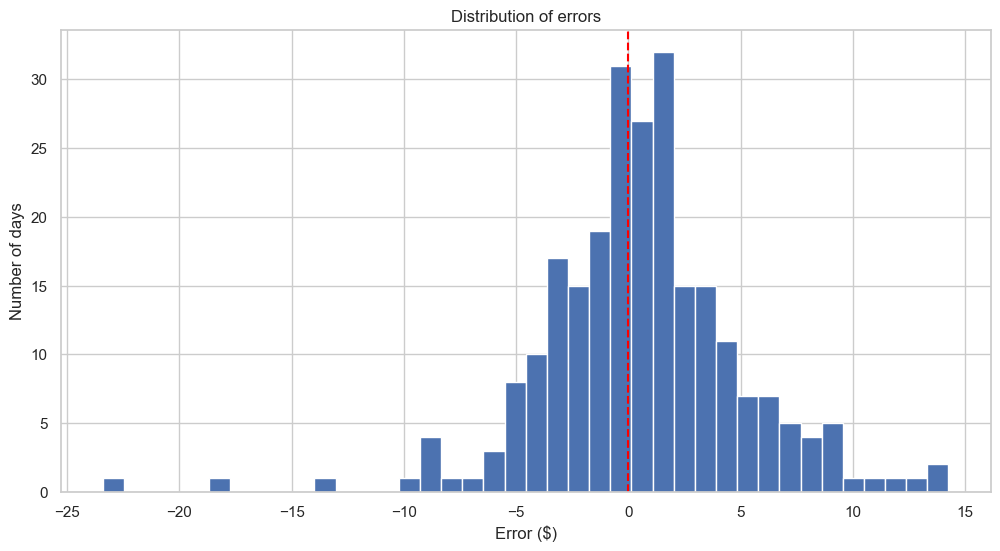

In [12]:
# Distribution of prediction errors
residuals = y_test - y_pred

plt.hist(residuals, bins=40)
plt.axvline(0, color="red", linestyle="--")
plt.title("Distribution of errors")
plt.xlabel("Error ($)")
plt.ylabel("Number of days")
plt.show()

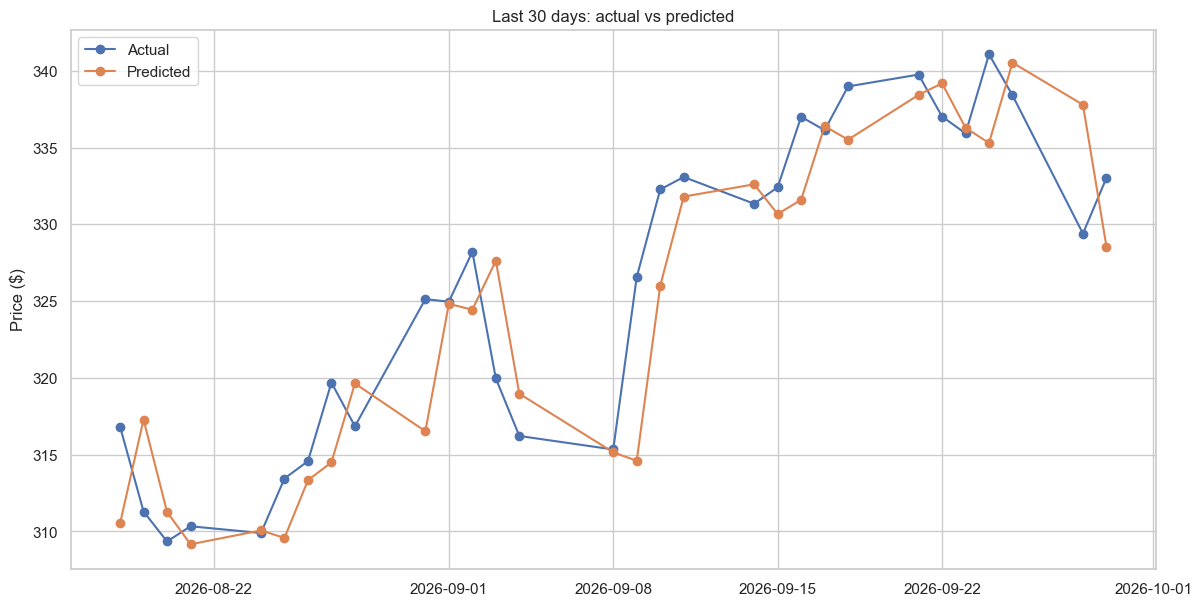

In [13]:
# Zoom on the last 30 days
plt.figure(figsize=(14, 7))
plt.plot(y_test.index[-30:], y_test[-30:], marker="o", label="Actual")
plt.plot(y_test.index[-30:], y_pred[-30:], marker="o", label="Predicted")
plt.legend()
plt.title("Last 30 days: actual vs predicted")
plt.ylabel("Price ($)")
plt.show()

Zooming in shows the predicted line essentially **lags the actual line by one day**, the classic sign of a model that repeats the last known value.

## Step 8: Reframing the problem, predicting tomorrow's return

Predicting the price level is "easy" because of autocorrelation. A harder and more meaningful question is: **will the stock go up or down tomorrow, and by how much?**

Price-level features are replaced by scale-free ones:

- `Gap_MA_5` / `Gap_MA_20`: how far the close is from its moving average, in %
- **Target:** tomorrow's return

**Baseline:** predict a 0% return every day.

In [14]:
df["Gap_MA_5"] = df["Close"] / df["MA_5"] - 1
df["Gap_MA_20"] = df["Close"] / df["MA_20"] - 1
df["Target_return"] = df["Return"].shift(-1)

df2 = df.dropna().copy()

FEATURES_R = ["Return", "Volatility_5", "Gap_MA_5", "Gap_MA_20"]

X2 = df2[FEATURES_R]
y2 = df2["Target_return"]

split2 = int(len(df2) * TRAIN_RATIO)
X2_train, X2_test = X2.iloc[:split2], X2.iloc[split2:]
y2_train, y2_test = y2.iloc[:split2], y2.iloc[split2:]

model2 = LinearRegression()
model2.fit(X2_train, y2_train)
y2_pred = model2.predict(X2_test)

baseline2 = np.zeros(len(y2_test))

pd.DataFrame(
    {
        "R2": [r2_score(y2_test, y2_pred), r2_score(y2_test, baseline2)],
        "MAE": [mean_absolute_error(y2_test, y2_pred), mean_absolute_error(y2_test, baseline2)],
    },
    index=["Linear Regression", "Baseline (0%)"],
).round(5)

,R2,MAE
Linear Regression,-0.01489,0.01127
Baseline (0%),-0.00521,0.01119


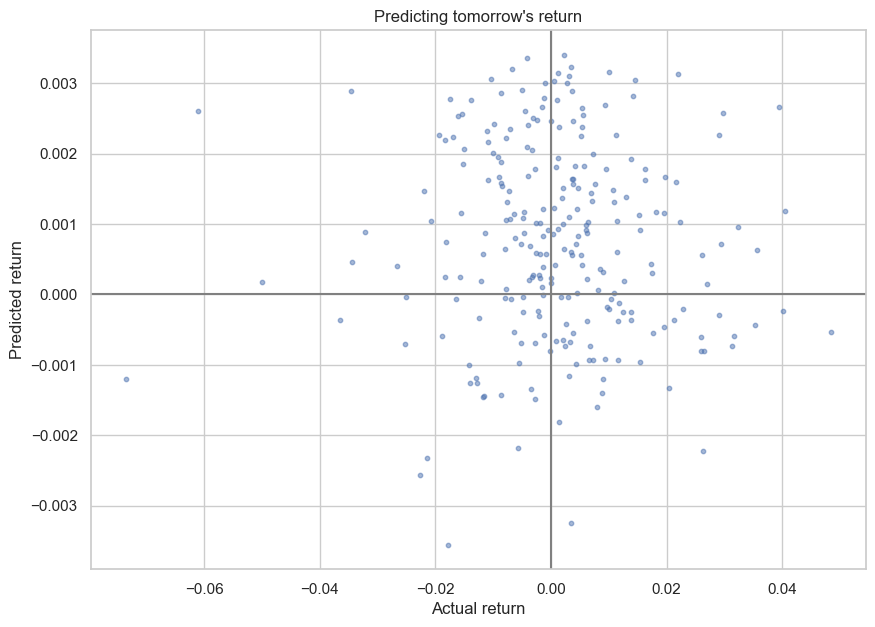

In [15]:
plt.figure(figsize=(10, 7))
plt.scatter(y2_test, y2_pred, s=10, alpha=0.5)
plt.axhline(0, color="gray")
plt.axvline(0, color="gray")
plt.xlabel("Actual return")
plt.ylabel("Predicted return")
plt.title("Predicting tomorrow's return")
plt.show()

> **Interpretation:** an R² close to zero (or negative) and predictions squeezed around 0% show that past returns and moving averages carry almost no information about tomorrow's return, which is consistent with the *weak-form efficient market hypothesis*.

## Step 9: Adding market context (S&P 500 and VIX)

Can broader market information help? Two market indicators are added:

- **S&P 500 daily return** (`^GSPC`): overall market direction
- **VIX** (`^VIX`): the "fear index", the market's expected volatility

In [16]:
sp500 = yf.Ticker("^GSPC").history(start=START, end=END)
vix = yf.Ticker("^VIX").history(start=START, end=END)

sp500.index = sp500.index.tz_localize(None).normalize()
vix.index = vix.index.tz_localize(None).normalize()

market = pd.DataFrame({
    "SP500_return": sp500["Close"].pct_change(),
    "VIX_level": vix["Close"],
    "VIX_change": vix["Close"].pct_change(),
})

# Merge market data with AAPL data
df2.index = df2.index.normalize()
df3 = df2.join(market, how="inner").dropna()

print(f"Rows before merge: {len(df2)}, after merge: {len(df3)}")
df3[["Return", "SP500_return", "VIX_level", "Target_return"]].head()

Rows before merge: 1233, after merge: 1233


,Return,SP500_return,VIX_level,Target_return
Date,,,,
2021-10-28,0.024992,0.009829,16.530001,-0.018156
2021-10-29,-0.018156,0.001949,16.260000,-0.005607
2021-11-01,-0.005607,0.001800,16.410000,0.007116
2021-11-02,0.007116,0.003680,16.030001,0.009799
2021-11-03,0.009799,0.006461,15.100000,-0.003499


In [17]:
# How strongly is AAPL linked to the market?
same_day = df3["Return"].corr(df3["SP500_return"])
next_day = df3["Target_return"].corr(df3["SP500_return"])

print(f"Correlation AAPL vs S&P 500, same day: {same_day:.3f}")
print(f"Correlation AAPL tomorrow vs S&P 500 today: {next_day:.3f}")

Correlation AAPL vs S&P 500, same day: 0.717
Correlation AAPL tomorrow vs S&P 500 today: -0.009


AAPL moves strongly **with** the market on the same day, but today's market return says very little about AAPL's return **tomorrow**.

In [18]:
FEATURES_MARKET = FEATURES_R + ["SP500_return", "VIX_level", "VIX_change"]

split3 = int(len(df3) * TRAIN_RATIO)
y3 = df3["Target_return"]
y3_test = y3.iloc[split3:]

def evaluate(features):
    """Train a linear regression on `features` and return (R2, MAE) on the test set."""
    X = df3[features]
    model = LinearRegression()
    model.fit(X.iloc[:split3], y3.iloc[:split3])
    pred = model.predict(X.iloc[split3:])
    return r2_score(y3_test, pred), mean_absolute_error(y3_test, pred)

baseline3 = np.zeros(len(y3_test))

comparison = pd.DataFrame(
    [
        evaluate(FEATURES_R),
        evaluate(FEATURES_MARKET),
        (r2_score(y3_test, baseline3), mean_absolute_error(y3_test, baseline3)),
    ],
    index=["Stock only", "Stock + Market", "Baseline (0%)"],
    columns=["R2", "MAE"],
)

comparison.round(5)

,R2,MAE
Stock only,-0.01489,0.01127
Stock + Market,-0.03166,0.01142
Baseline (0%),-0.00521,0.01119


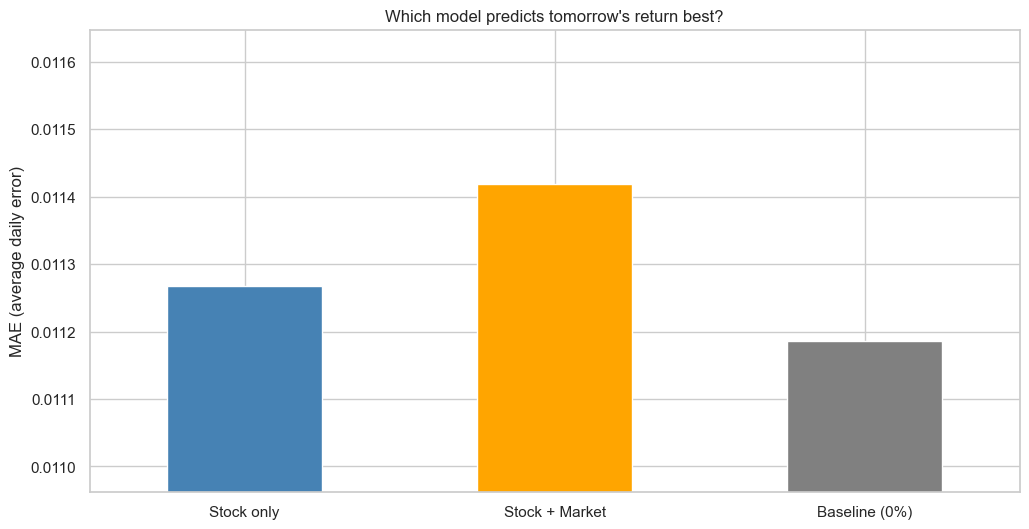

In [19]:
comparison["MAE"].plot(kind="bar", color=["steelblue", "orange", "gray"])
plt.ylabel("MAE (average daily error)")
plt.title("Which model predicts tomorrow's return best?")
plt.xticks(rotation=0)
plt.ylim(comparison["MAE"].min() * 0.98, comparison["MAE"].max() * 1.02)
plt.show()

## Conclusion

- **Price prediction:** linear regression reaches a very high R², but it does **not** beat the naive "tomorrow = today" baseline. A high R² on stock prices is misleading on its own.
- **Return prediction:** the much harder task of predicting daily returns shows almost no predictive power from technical indicators, with or without market context (S&P 500, VIX).
- **Key takeaway:** always compare against a naive baseline and use a chronological split. These two habits separate a credible financial ML analysis from an over-optimistic one.

### Possible next steps

- Walk-forward (rolling) validation instead of a single split
- Non-linear models (Random Forest, Gradient Boosting, LSTM)
- Classification framing (up / down) with accuracy and precision metrics
- Additional signals: earnings dates, news sentiment, sector ETFs

---
*Disclaimer: this project is for educational purposes only and is not financial advice.*